--- QUBO Structure Analysis ---
Qubit Count (V): 10
Total Couplings (E): 12
Average Couplings per Qubit (2E/V): 2.40
Max Couplings per Qubit (d_max): 5
Matrix Density: 26.67%


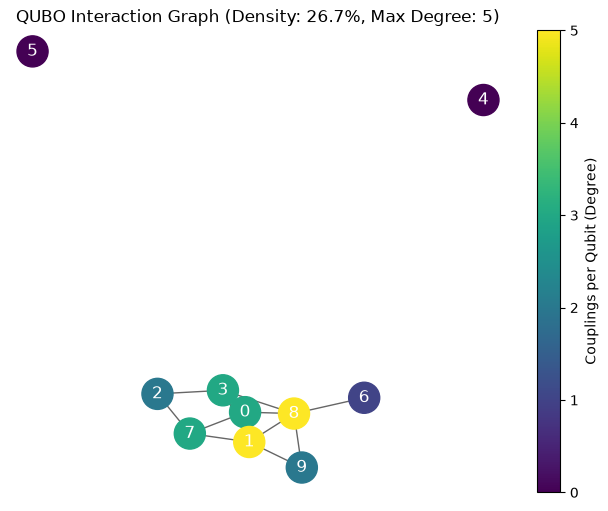

In [1]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

def analyze_and_plot_qubo(Q_matrix):
    """
    Q_matrix: 2D numpy array representing the QUBO matrix
    """
    N = Q_matrix.shape[0]
    
    # Build Interaction Graph (edges where Q_ij != 0 for i != j)
    G = nx.Graph()
    G.add_nodes_from(range(N))
    
    for i in range(N):
        for j in range(i + 1, N):
            if Q_matrix[i, j] != 0 or Q_matrix[j, i] != 0:
                G.add_edge(i, j, weight=Q_matrix[i, j] + Q_matrix[j, i])
                
    num_nodes = G.number_of_nodes()
    num_edges = G.number_of_edges()
    
    # Key Ratios & Metrics
    avg_coupling_ratio = (2 * num_edges) / num_nodes if num_nodes > 0 else 0
    density = nx.density(G)
    degrees = [d for n, d in G.degree()]
    max_degree = max(degrees) if degrees else 0
    
    print(f"--- QUBO Structure Analysis ---")
    print(f"Qubit Count (V): {num_nodes}")
    print(f"Total Couplings (E): {num_edges}")
    print(f"Average Couplings per Qubit (2E/V): {avg_coupling_ratio:.2f}")
    print(f"Max Couplings per Qubit (d_max): {max_degree}")
    print(f"Matrix Density: {density * 100:.2f}%")
    
    # Visualization: Color nodes by degree
    pos = nx.spring_layout(G, seed=42)
    plt.figure(figsize=(8, 6))
    nodes = nx.draw_networkx_nodes(G, pos, node_color=degrees, cmap=plt.cm.viridis, node_size=500)
    nx.draw_networkx_edges(G, pos, alpha=0.6)
    nx.draw_networkx_labels(G, pos, font_color="white")
    
    plt.colorbar(nodes, label="Couplings per Qubit (Degree)")
    plt.title(f"QUBO Interaction Graph (Density: {density*100:.1f}%, Max Degree: {max_degree})")
    plt.axis("off")
    plt.show()

# Example: Random Sparse Matrix (10 variables)
np.random.seed(0)
sample_Q = np.random.choice([0, 1], size=(10, 10), p=[0.7, 0.3])
sample_Q = np.triu(sample_Q, 1)

analyze_and_plot_qubo(sample_Q)

In [2]:
import networkx as nx
from mqt.problemsolver import QUBO;

# 1. Define your real-world case study graph (e.g., Robot navigation map)
G = nx.Graph()
G.add_edge("Robot1_Start", "Task_A", weight=5)
G.add_edge("Task_A", "Task_B", weight=2)
G.add_edge("Robot1_Start", "Task_B", weight=8)

# 2. Translate case study constraints into QUBO automatically
# Options for encoding: "one-hot", "domain-wall", or "binary"
qubo_builder = QUBO(G, encoding="one-hot")

# Add your domain constraints in natural language concepts
qubo_builder.add_visit_all_nodes_constraint()
qubo_builder.add_single_location_constraint()

# 3. Generate QUBO Matrix (Q)
Q_matrix = qubo_builder.get_qubo_matrix()
print("Generated QUBO Matrix shape:", Q_matrix.shape)

ImportError: cannot import name 'QUBO' from 'mqt.problemsolver' (c:\Users\Prüfer\requirements_analysis_qubo\venv\Lib\site-packages\mqt\problemsolver\__init__.py)